# 04 AI运维 - 系统告警监控


## 本篇资料与学习路线

本篇对应 **AI运维8小时精华版 → 4-0基础带你入行AI Linux运维_系统告警监控.pdf**，依据全部 **42 页**课件文字和页面图片，以及“资料 → 项目内容 → 云监控.rar”中的 `云监控/测试脚本/cpu_test.sh` 整理。重复封面、总结和作业并入相关章节。

资料来源：[课程网盘](https://pan.baidu.com/s/1piPE1VDdCBoKDeGf-34QPA?pwd=1234)，提取码 `1234`。

前一篇完成项目上线后，这一篇学习怎样持续观察服务器状态、在异常发生时收到通知，再根据监控数据排查问题。原课围绕阿里云云监控控制台展开。

| 顺序 | 课件主题 | 页码 | 要完成的事情 |
| --- | --- | --- | --- |
| 1 | 阿里云监控组件 | 2-8 | 开通云监控并进入控制台 |
| 2 | 云主机监控策略 | 9-13 | 给目标主机安装 Agent，看到资源使用率 |
| 3 | 系统报警服务配置 | 14-24 | 创建联系人、联系组和 CPU 分级告警规则 |
| 4 | 系统运维常见问题 | 25-30 | 排查 CPU 负载过高与内存占用过高 |
| 5 | ECS 服务器巡检报告 | 31-33 | 认识巡检报告的五部分内容 |
| 6 | 云服务器监控可视化大屏 | 34-41 | 添加指标图表并保存自定义大盘 |


## 一、阿里云监控组件

### 1.1 云监控解决什么问题

**原课依据：第 3 页。** 云监控（CloudMonitor）用于实时观察阿里云资源的运行状态，包括服务器、数据库和网络等。当资源出现异常、指标满足报警条件时，云监控会通知对应人员，帮助及时发现问题、保障业务稳定运行。

这里要区分两个操作：**监控**负责采集并展示数据，**报警规则**负责判断数据是否异常、应该通知谁。看到了 CPU 曲线，并不等于已经配置了报警通知。

### 1.2 开通并进入控制台

**原课依据：第 4-6 页。** 按课件顺序操作：

1. 打开阿里云，在产品列表的“运维与监控管理”中找到“云监控”。
2. 进入产品页，按页面入口开通服务。课件还展示了首次免费试用入口；当前是否提供试用、额度是多少，以实际产品页面为准。
3. 点击阿里云右上方“控制台”。在产品列表里选择“运维与监控管理 → 云监控”，进入云监控控制台。

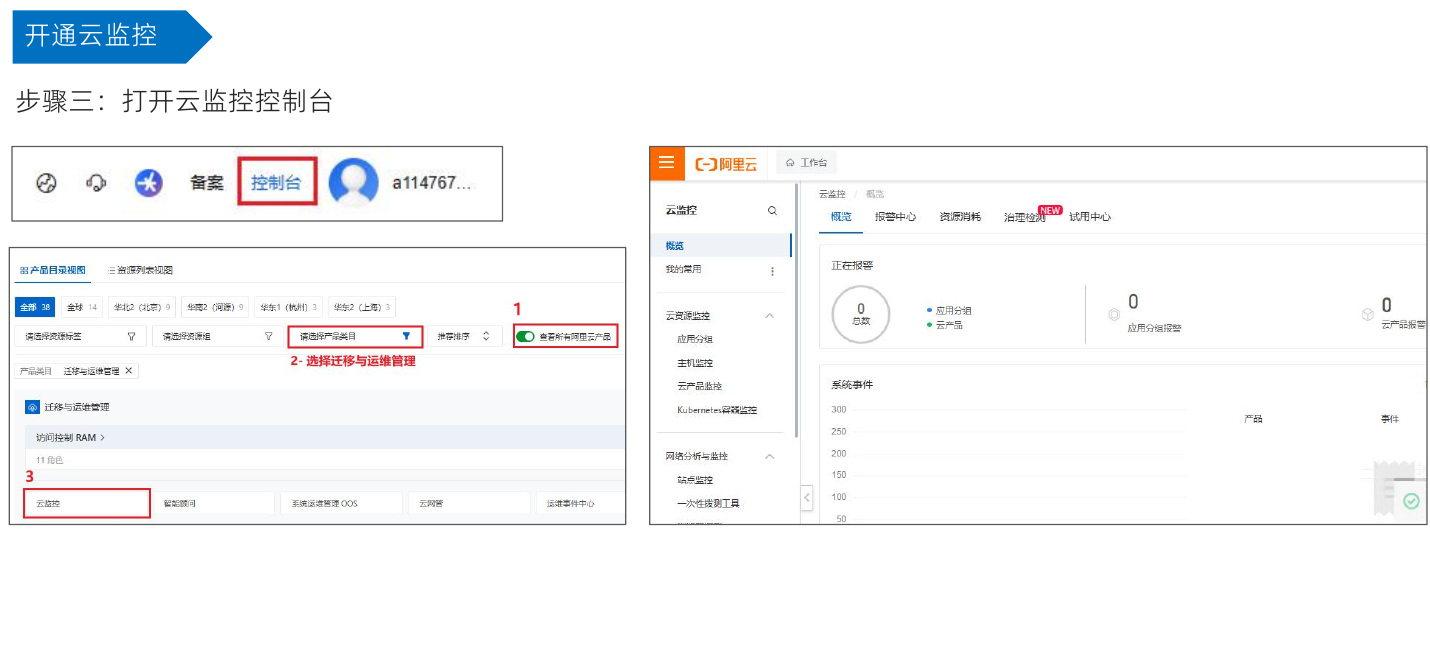

**验证：** 能看到云监控概览以及主机监控、报警服务等菜单。控制台初始报警数量为 `0` 是可能的；之后还需要安装采集插件和创建规则。

**本节作业：** 完成云监控服务开通，并进入控制台。


## 二、开通云主机监控

**原课依据：第 10-12 页。** 接下来把监控落到实际 ECS 主机上。Agent 是安装在主机上的监控采集插件，用来采集操作系统指标并上报云监控。

### 2.1 找到需要监控的主机

进入“云资源监控 → 主机监控”，查看主机列表。课件列表展示了前面中州养老项目的三台 ECS；安装范围还包含上一篇准备的私有大模型 ECS，共四台目标服务器。

在列表中确认主机名、实例 ID、地域和 IP，避免给错误实例安装插件。尚未安装或尚未上报数据时，CPU、内存和磁盘使用率可能显示“无数据”。

### 2.2 安装 Agent

在目标主机的“Agent 状态”列使用“自动安装”，给需要监控的主机安装插件。课件通过控制台完成安装，没有提供手动安装命令。

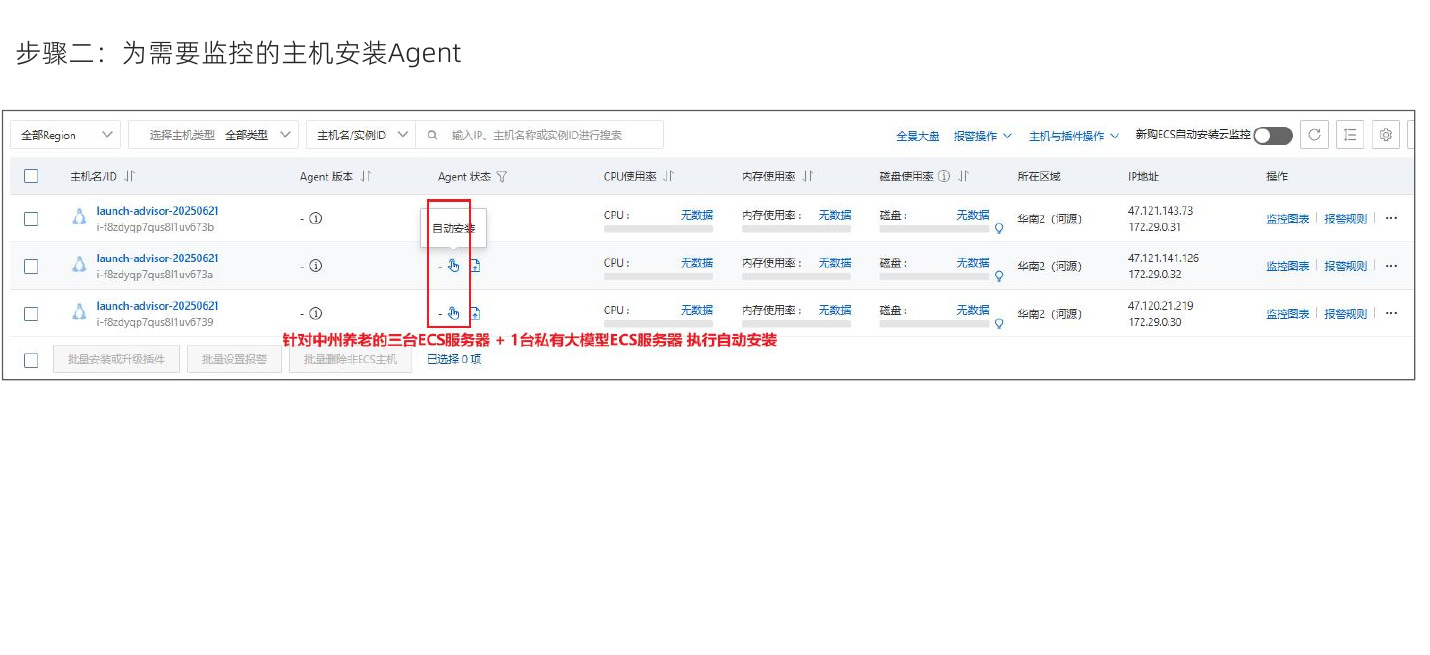

### 2.3 等待数据上报并验证

安装后等待片刻，再刷新列表。课件中 CPU 使用率、内存使用率和磁盘使用率由“无数据”变为实际数值，可以进一步通过“监控图表”查看曲线。

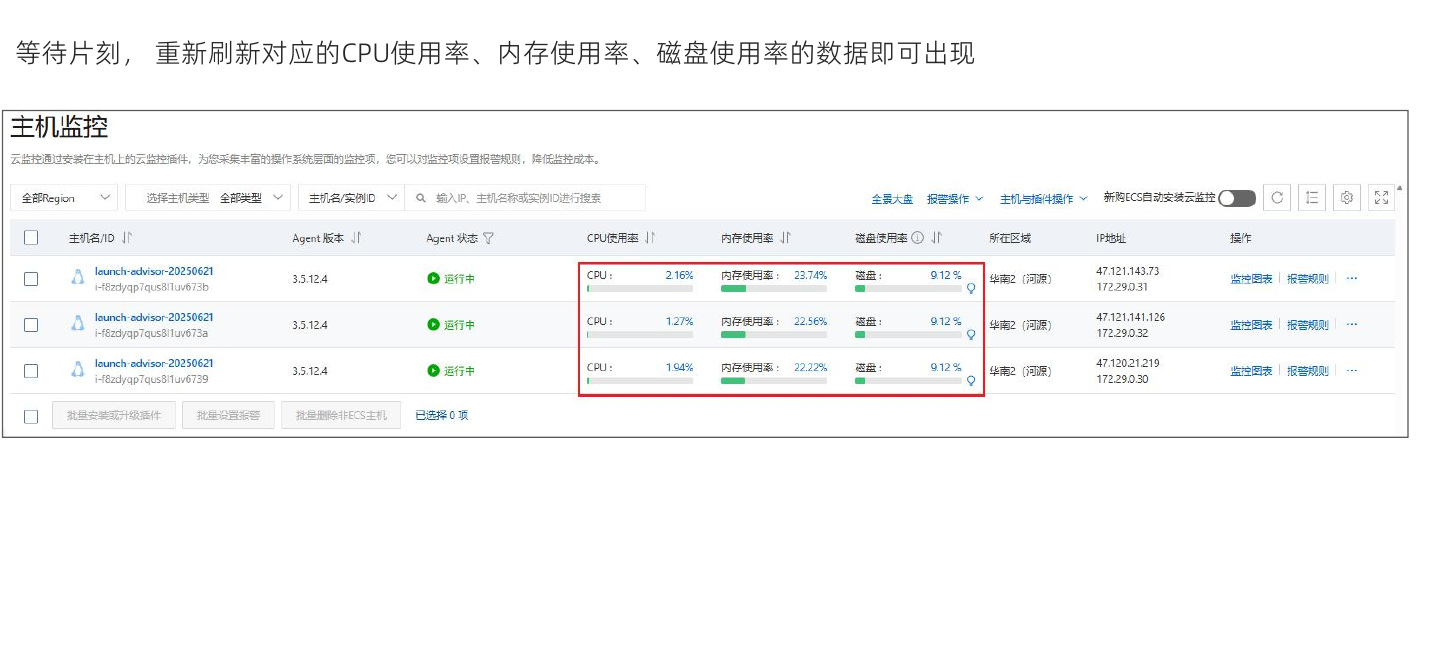

**验证顺序：** 目标主机存在 → Agent 状态正常 → 指标出现数值 → 监控图表出现数据。后面配置规则时，应选择已经能够正常采集的指标。

**整理补充：** “无数据”不等于使用率为 `0%`。先确认目标主机、Agent 状态和查询时间范围，再判断是否需要排查采集或上报问题。

**本节作业：** 完成云主机监控，确认目标主机的 CPU、内存和磁盘指标可以查看。


## 三、系统报警服务：联系人与联系组

**原课依据：第 15-16 页。** 报警服务根据监控指标的预设条件自动发出通知。课件说明，监控对象可以包括阿里云资源、线下 IDC、其他云厂商资源以及自定义监控数据；本节实际演示的是 ECS。

配置顺序是：**报警联系人 → 报警联系组 → 报警规则**。先把收件人和分组准备好，创建规则时才能选择通知对象。

### 3.1 创建报警联系人

报警联系人保存需要收到告警的人员信息。

1. 打开“报警服务 → 报警联系人”。
2. 在“报警联系人”页签点击“创建联系人”。
3. 填写姓名、通知地区以及需要的手机、邮箱等信息，按控制台要求完成相关校验。
4. 保存联系人，确认其出现在联系人列表中。

课件页面还展示了钉钉、飞书、企业微信、Slack/Webhook 等第三方通知入口。本课 CPU 示例主要使用邮件、短信和电话。

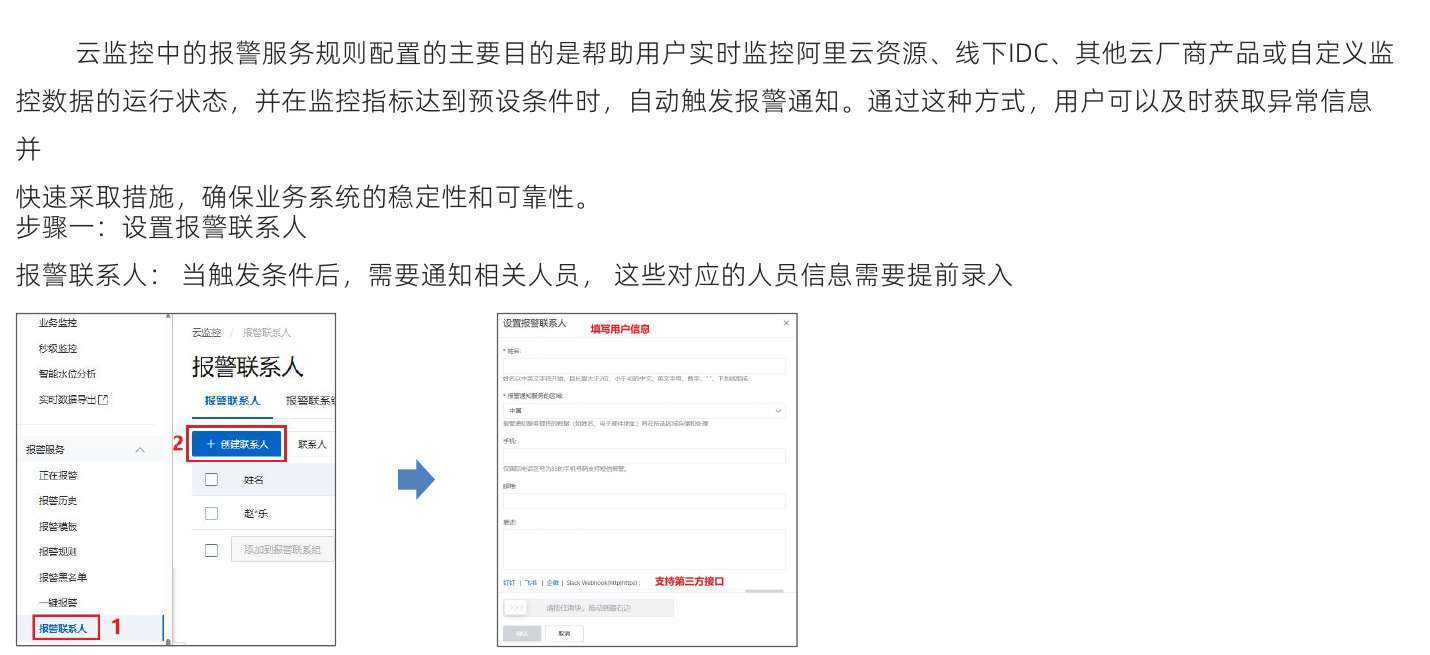

### 3.2 创建报警联系组

报警联系组把多个联系人组织成一个通知对象。不同业务或人员类型可以分别建组，规则触发后可以通知组内多个人。

1. 切换到“报警联系组”页签。
2. 点击“新建联系人组”，填写组名和备注。
3. 从已有联系人中选择组成员，移入已选联系人列表。
4. 确认保存，检查组内人员是否正确。

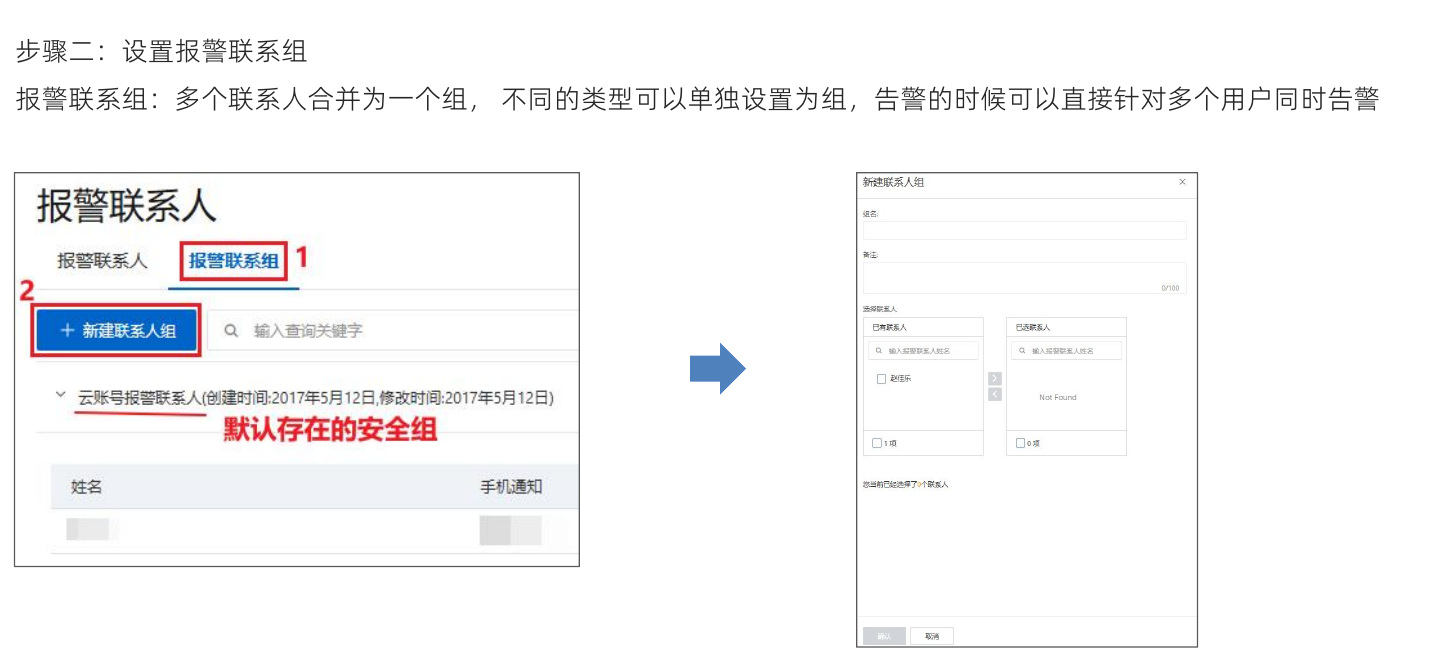

> 课件截图把默认联系人组标注成“默认存在的安全组”。这里指的是报警联系组，不是 ECS 控制入站、出站流量的网络安全组。


## 四、创建 CPU 分级报警规则

### 4.1 选择产品、资源范围和指标

**原课依据：第 17-18 页。** 报警规则规定“监控谁、看哪个指标、什么条件触发、通知哪些人”。

1. 进入“报警服务 → 报警规则”，点击“创建报警规则”。
2. 产品选择“云服务器 ECS”。
3. 设置资源范围。课件演示“全部资源”，页面也提供“应用分组”和“实例”范围。
4. 在规则描述中点击“添加规则 → 简单指标”。
5. 填写规则名称，在监控指标中选择目标指标。

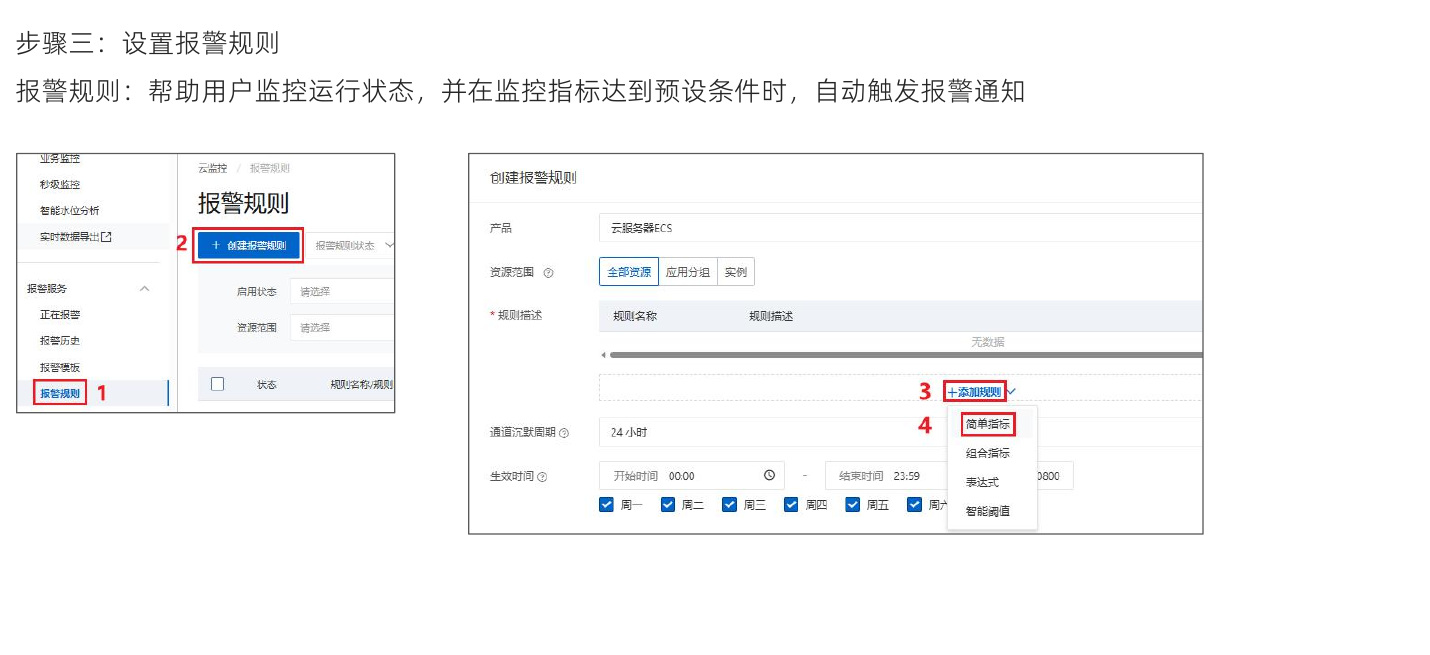

| 页面选项 | 课件中的含义 |
| --- | --- |
| 简单指标 | 对单个指标设置报警条件 |
| 组合指标 | 把多个指标组合起来监控 |
| 指标类别 | 页面列出实例维度、磁盘、地域、实例、user、Network、erdma、GPU、进程、连接数等类别，各类别下再选择具体指标 |

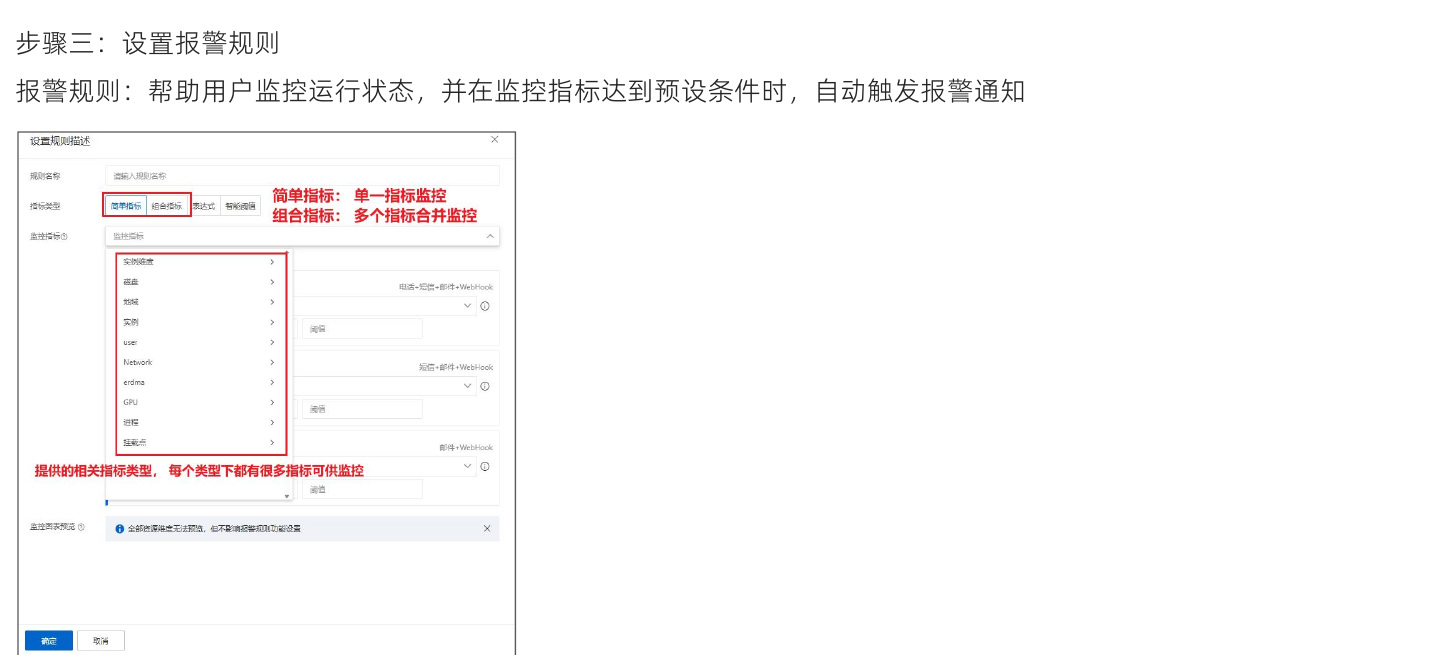

本次 CPU 示例选择的是 **实例维度 / (ECS)CPU使用率**，统计方法为**平均值**，单位为 `%`。

### 4.2 按异常程度分级通知

**原课依据：第 19 页。** 课程要求：连续 1 分钟 CPU 使用率超过 80% 时发邮件；连续 3 分钟超过 90% 时发短信和邮件；连续 5 分钟超过 95% 时发电话、短信和邮件。

课件实际配置截图使用 `>=`，并把每个统计周期设置为 **1 分钟**：

| 报警级别 | 连续满足的周期 | 实际配置条件 | 示例通知方式 |
| --- | --- | --- | --- |
| 普通 Info | 连续 1 个周期，每周期 1 分钟 | CPU 平均使用率 `>= 80%` | 邮件 |
| 警告 Warn | 连续 3 个周期，每周期 1 分钟 | CPU 平均使用率 `>= 90%` | 短信 + 邮件 |
| 紧急 Critical | 连续 5 个周期，每周期 1 分钟 | CPU 平均使用率 `>= 95%` | 电话 + 短信 + 邮件 |

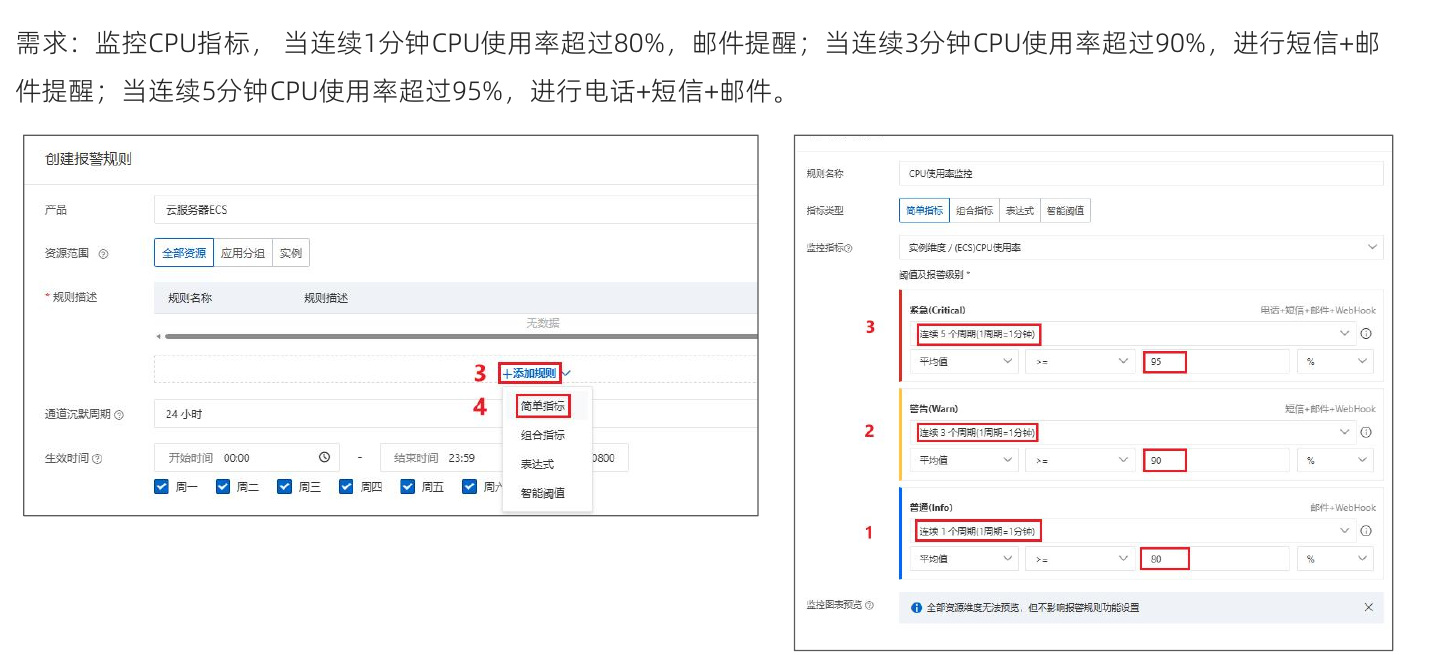

页面还标出了各级别可使用的 Webhook 通知。本次按课件的邮件、短信、电话需求配置即可。

**容易混淆的地方：** “连续 3 个 1 分钟周期达到阈值”要求连续三个采样周期都满足条件。它与“把 3 分钟作为一个周期，只检查一次平均值”不是同一种配置。

**原课文字与截图差异：** 原文写“超过”，截图使用“达到或超过”。复现这套规则时采用截图的 `>=`，不要在文字和配置中混用 `>` 与 `>=`。


## 五、设置生效时间并验证报警

### 5.1 完成规则的通知设置

**原课依据：第 20、23 页。** 保存指标条件后，在创建规则页面继续完成以下项目：

| 设置项 | 作用 | 课件示例 |
| --- | --- | --- |
| 通道沉默周期 | 规则持续处于同一报警状态时，控制重复通知间隔 | `24 小时` |
| 生效时间 | 控制规则在哪些日期、时段生效 | 周一至周日，`00:00-23:59`，时区 `+0800` |
| 报警联系人组 | 指定收到告警的人员组 | 选择前面准备的联系人组 |
| 高级设置 | 页面还有报警回调等选项 | 根据本次通知需求选择 |

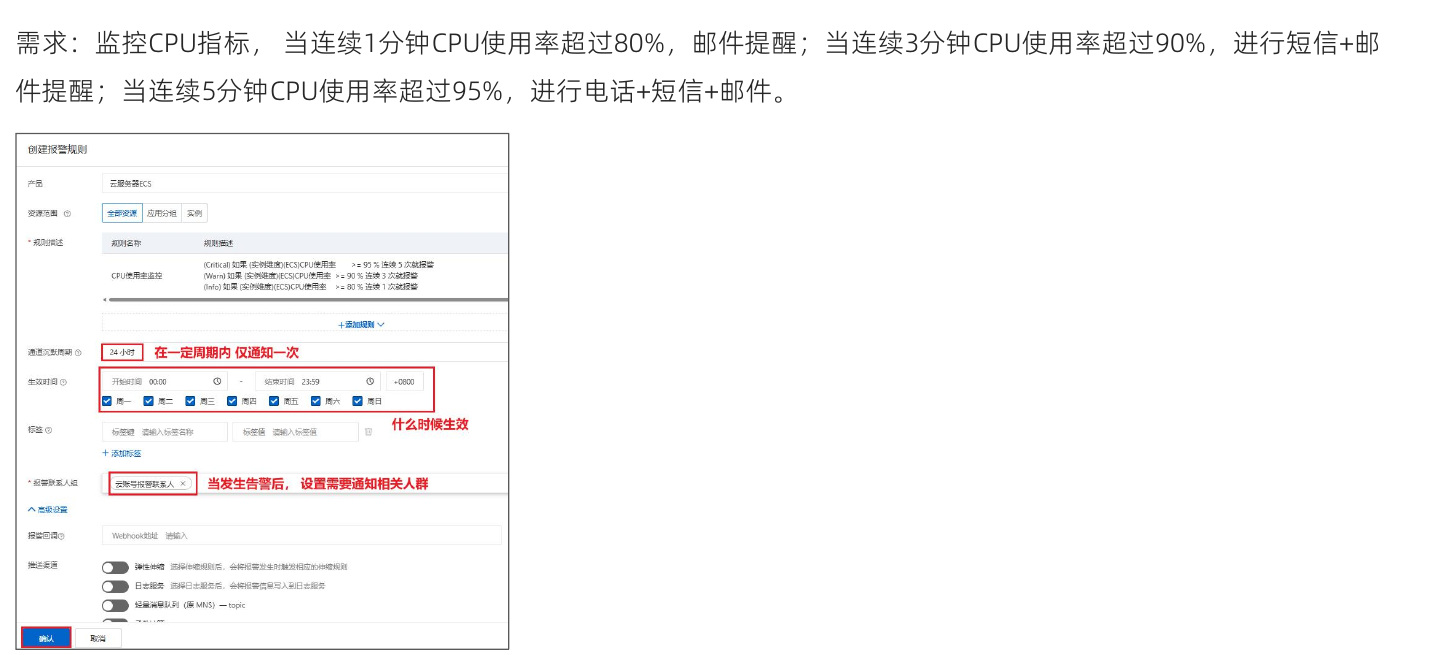

最后点击“确认”，在报警规则列表中检查资源范围、指标、三级阈值、连续周期、联系人组和启用状态。

**整理补充：** 沉默周期控制重复通知，不能当作指标采集周期，也不是在首次异常后等待 24 小时才报警。不同级别变化、恢复通知等具体行为，以控制台当前规则说明为准。

### 5.2 使用资料中的 CPU 测试脚本验证

**原课依据：第 21 页及配套 `云监控.rar`。** 课程要求把 CPU 测试脚本上传到服务器并启动，等待资源占用上升，观察邮件和短信等通知。配套文件是 `云监控/测试脚本/cpu_test.sh`，源码如下：

```bash
#!/bin/bash

# 启动 2 个 `yes` 进程，使 CPU 100% 占用
yes > /dev/null &
yes > /dev/null &
yes > /dev/null &
yes > /dev/null &

# 让脚本保持运行
wait
```

`yes` 会持续输出内容，重定向到 `/dev/null` 后输出被丢弃；`&` 让各进程后台运行，`wait` 让脚本等待后台任务结束。**原脚本注释写“2 个”，实际有 4 行 `yes`，会启动 4 个进程。**

**整理补充：** 四个忙循环通常最多占满约四个逻辑 CPU。实例核数更多时，总 CPU 使用率不一定达到 `80%`、`90%` 或 `95%`。先看实际曲线，不把注释里的“100%”当成所有规格服务器都能保证的结果。

以下目录是整理时的示例，按服务器实际上传位置替换。仅在能够承受测试的服务器中运行：

```bash
cd /opt/monitor-test
bash cpu_test.sh
```

1. 在目标主机的监控图表中观察 CPU 使用率是否确实升高。
2. 等待相应的连续周期满足后，查看“正在报警”或“报警历史”。
3. 检查通知中的实例、指标、当前值和级别是否与测试一致，再确认对应联系人收到通知。
4. 测试后停止负载进程，确认 CPU 使用率回落。

原脚本没有记录后台 PID，也没有退出清理逻辑。停止时另开一个终端，核对脚本和四个 `yes` 子进程的 PID、PPID：

```bash
ps -eo pid,ppid,comm,args | grep -E '[c]pu_test.sh|[y]es'
```

确认四个 `yes` 都属于本次脚本后，替换下面占位符，发送正常终止信号：

```bash
kill <YES_PID_1> <YES_PID_2> <YES_PID_3> <YES_PID_4>
```

四个子进程结束后，脚本的 `wait` 才能结束。不要仅凭按过 `Ctrl+C` 就认定所有后台负载已停止；再次检查这些进程和 CPU 曲线。

课件展示了普通、警告和紧急的邮件，以及警告、紧急的短信。其中警告短信当前值约为 `98.55%`，紧急短信当前值为 `100%`，用于展示真实指标触发规则后的通知效果。

> 上面的源码取自课程配套文件；运行目录示例、命令解释和停止方法属于整理补充。测试结果以实际监控与通知为准。

### 5.3 常用指标的一键报警

**原课依据：第 22 页。** 对常用指标，云监控提供“一键报警”方案。在“报警服务 → 一键报警”中找到对应产品，开启该产品的方案。

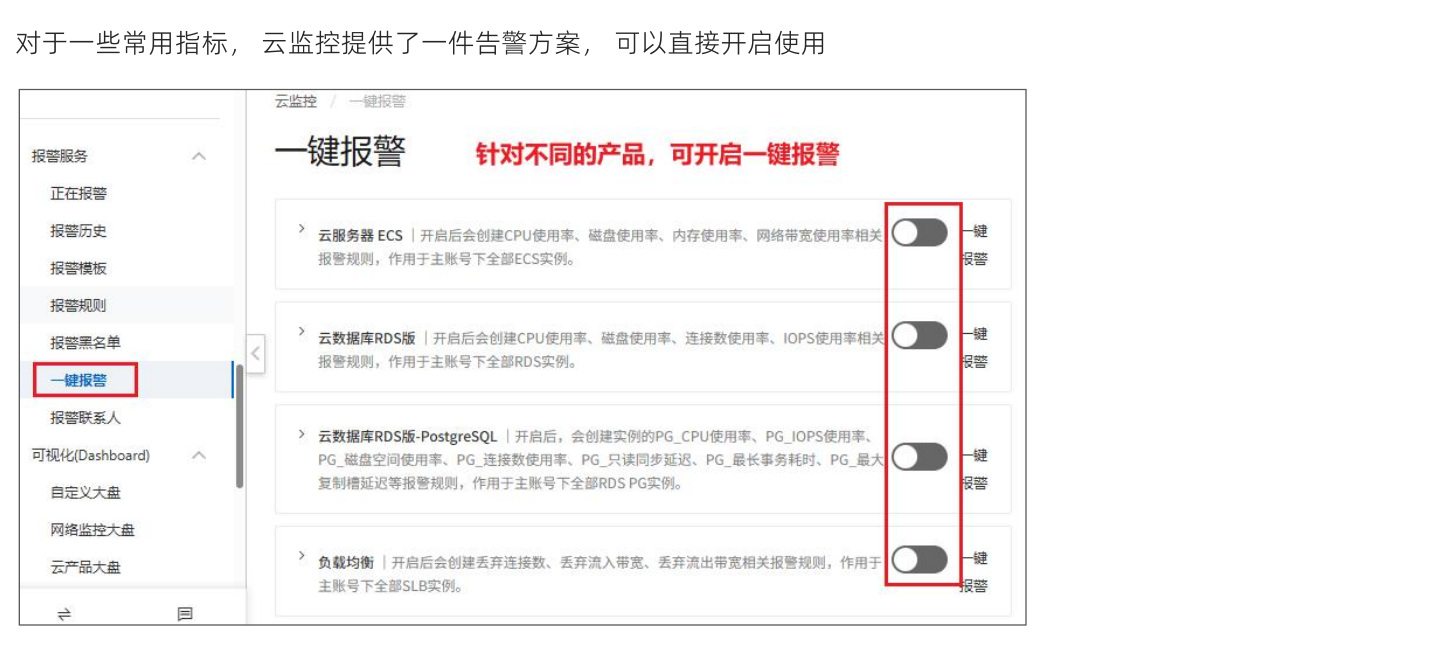

课件截图展示的产品与覆盖内容包括：

- **云服务器 ECS**：CPU、磁盘、内存和网络带宽使用率。
- **云数据库 RDS**：CPU、磁盘、连接数和 IOPS 使用率。
- **RDS PostgreSQL**：还包括读写延迟、长事务等指标。
- **负载均衡**：连接数、流入和流出带宽等指标。

启用后核对实际生成的规则及资源范围。课件截图中的 ECS 方案作用于主账号下全部 ECS 实例。

### 5.4 本节作业

按第 24 页要求，尝试为 **CPU、GPU、内存、网络**设置报警规则，分别练习 **1 分钟、5 分钟、15 分钟**的告警方式。

设置前先确认该主机有相应硬件、采集条件和指标数据。记录自己选择的是“单个统计周期长度”还是“连续满足的周期数”，再观察报警结果。


## 六、系统运维常见问题：CPU 负载

### 6.1 先确认负载是否持续偏高

**原课依据：第 26 页。** 使用 `top` 或 `htop` 查看服务器状态。

在需要排查的 Linux 服务器上执行：

```bash
top
```

如果服务器已经安装 `htop`，也可以执行：

```bash
htop
```

`top` 顶部的 `load average` 有三个值，依次表示 **1 分钟、5 分钟、15 分钟的平均负载**。观察多个时间窗口，可以判断当前是突然升高，还是已经持续了一段时间。

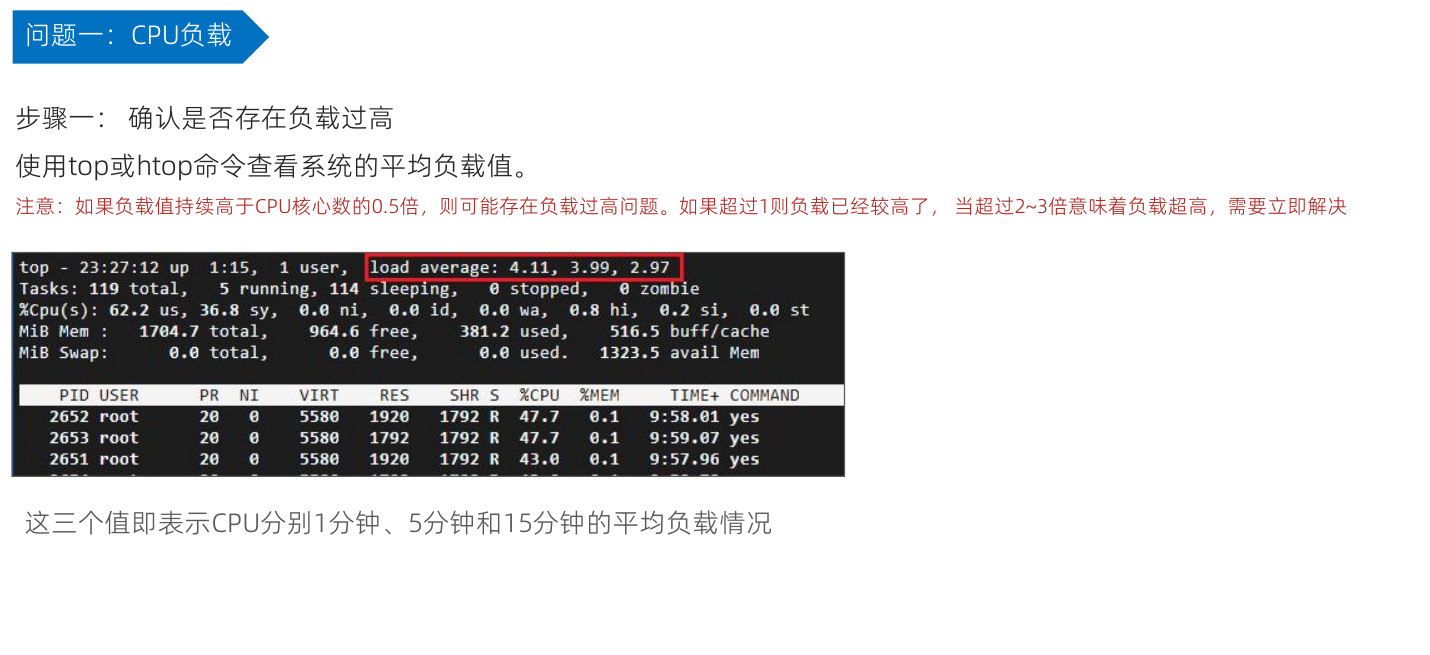

课件给出的经验判断是：持续超过 CPU 核心数的 `0.5` 倍，应关注负载；超过核心数的 `1` 倍，负载已经较高；达到 `2-3` 倍，需要及时排查。

> **整理澄清：** 平均负载不是 CPU 使用率百分比，应结合 CPU 核心数理解。例如 4 核服务器的负载 `2` 相当于核心数的 `0.5` 倍，负载 `4` 相当于 `1` 倍。课件总结页简写成“超过 0.5”，不能理解成任何服务器的负载绝对值一超过 `0.5` 就异常。该阈值是课程经验值，还要结合业务和持续时间判断。

### 6.2 按进程、容量和 I/O 排查

**原课依据：第 27 页。** 先看 CPU 使用率，再看进程和资源状态。负载高并不一定意味着 CPU 正在满负荷计算。

| 课件列出的原因 | 具体表现 | 课件给出的排查或处理方向 |
| --- | --- | --- |
| 异常进程或服务占用大量 CPU | 个别进程使用率很高，带动整体使用率上升 | 使用 `top`/`htop` 定位；在 `top` 中按 `Shift+P` 按 CPU 排序，处理异常进程 |
| 系统资源不足 | 实例 CPU 性能不足以支撑业务 | 升级实例规格，或优化业务逻辑 |
| 磁盘或网络 I/O 瓶颈 | 平均负载高，但实际 CPU 使用率不高 | 优化磁盘读写、升级高性能云盘；增加公网带宽或调整内网流量分布 |
| 僵尸进程或不可中断睡眠状态 | CPU 使用率不高，但负载偏高 | 检查进程状态；对阻塞任务恢复其依赖资源，必要时安排重启 |
| 病毒或恶意程序攻击 | CPU 使用率高，但常规进程观察无法解释 | 对照云监控异常时间点，排查异常域名/IP 通信；确认后备份数据、回滚实例并扫描病毒 |

课件给出下列进程状态检查示例：

```bash
ps -axjf | grep "D+"
```

**整理澄清：** `D` 表示不可中断睡眠，常与等待 I/O 有关；`Z` 才表示僵尸进程。课件这条命令只搜索含 `D+` 的文本，不能同时识别所有 `D` 和 `Z` 状态。僵尸进程本身通常不占用 CPU，不能把它与正在等待 I/O 的任务混为一谈。

如果需要直接核对状态列，可以补充查看：

```bash
ps -eo pid,ppid,stat,comm
```

课件还提到终止异常进程的命令。命令名称应使用小写，示意如下；把占位符替换成已经核实的进程 PID：

```bash
kill -9 <PID>
```

**整理补充：** `-9` 会强制结束进程，使其无法执行正常退出清理。处理业务服务时，先确认所属服务和影响，再优先使用该服务的正常停止方式；必要时才使用强制终止。阻塞在 `D` 状态的任务还需要处理等待的资源，发送信号不代表它会立即退出。

**验证：** 处理后继续观察进程占用、业务是否正常以及负载走势。平均负载是时间窗口的统计值，不会在处理完成的瞬间全部归零。


## 七、系统运维常见问题：内存占用过高

### 7.1 确认是否出现内存压力

**原课依据：第 28、30 页。** 可以通过 `top`、`htop` 或云监控查看内存。课件把内存使用率持续接近或达到 `100%` 称为“内存爆满”，并提示超过 `80%` 时占用已经较高。

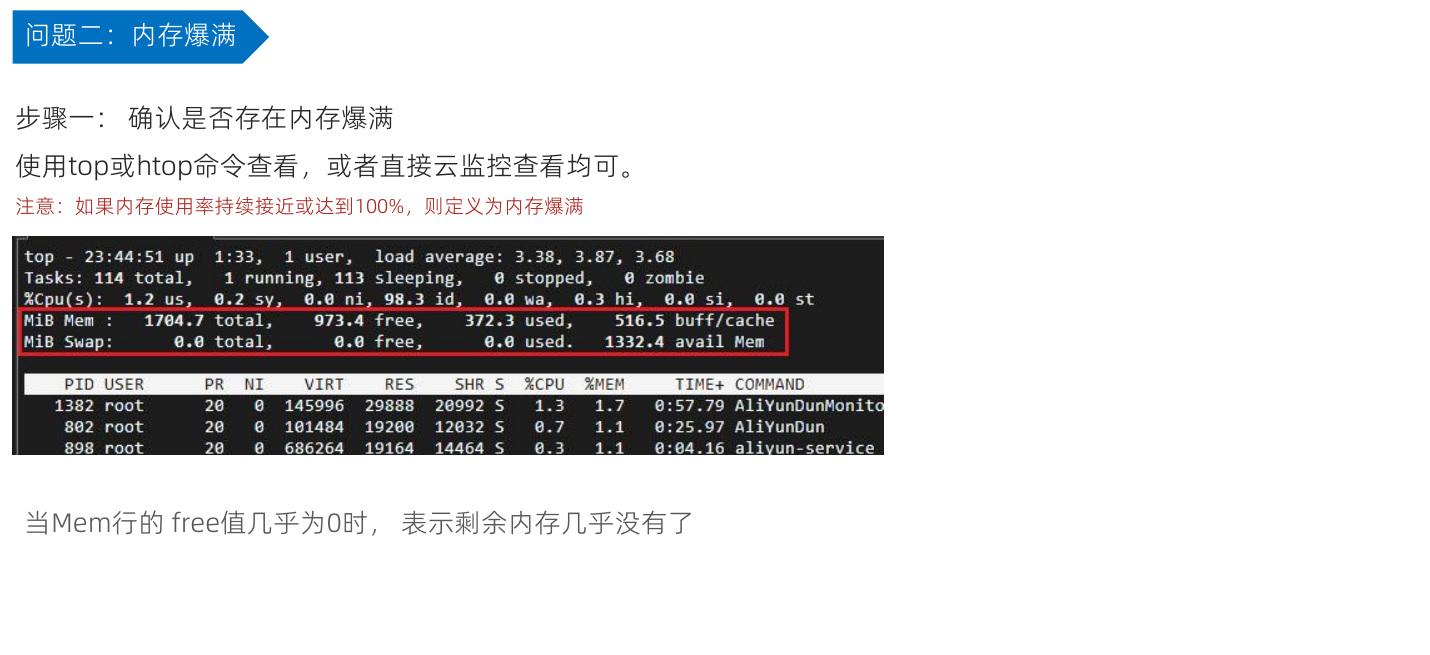

课件强调 `Mem` 行的 `free` 值接近 `0`。但 Linux 会把空闲内存用于缓存，所以还需要结合可用内存理解，不能单凭 `free` 很小就认定异常。

课件截图是字段位置示例，其中 `free` 约为 `973.4 MiB`、`avail Mem` 约为 `1332.4 MiB`，并未实际展示内存爆满。判断故障时应读取自己服务器的数据。

**整理补充：** 可在目标 Linux 主机上执行下列命令，结合 `available`、缓存和 Swap 使用情况判断实际内存压力：

```bash
free -h
```

### 7.2 按占用来源处理

**原课依据：第 29 页。** 在 `top` 中按 `Shift+M`，按内存占用排序（课件写作按 `M`），先找出持续占用内存的进程，再判断原因。

| 课件列出的原因 | 表现 | 课件给出的处理方向 |
| --- | --- | --- |
| 异常进程占用大量内存 | 个别进程长期占用大量内存 | 使用 `top`/`htop` 定位进程，处理异常进程 |
| 系统内存不足 | 实例物理内存无法支撑业务 | 升级实例规格或优化业务逻辑 |
| 内存泄漏或代码缺陷 | 应用运行过程中不断消耗内存，占用持续升高 | 使用 Valgrind、JProfiler、jmap 等工具分析，再修复业务代码 |
| 已删除但未释放的文件 | 课件把它列入资源占用排查 | 使用 `lsof` 找到仍持有文件的进程，再处理相关进程 |
| 系统缓存或虚拟内存不足 | 缓存占用较多，或内存容量不足 | 课件提出设置 Swap、增加虚拟内存大小 |

课件给出的文件排查命令：

```bash
lsof | grep deleted
```

> **整理澄清：** 已删除但仍被进程打开的文件通常用于排查“文件已经删了，但磁盘空间没有释放”，不是通用的内存爆满原因。应根据实际证据处理持有文件的进程，不把它称作僵尸进程。正常文件缓存也不等于内存泄漏；Swap 可以缓解容量压力，但不能修复泄漏。

若确实需要结束异常进程，课件同样提到 `kill -9 <PID>`；先核实 PID 和服务影响，并优先正常停止。处理后同时观察可用内存、进程占用及业务恢复情况。


## 八、ECS 服务器巡检报告

**原课依据：第 32-33 页。** 巡检报告用于评估 ECS 实例及磁盘、网络等相关资源的健康状态和运行性能。它综合性能、安全风险和资源配置，帮助提高稳定性、安全性，优化资源，并支持合规审计。

报告的五部分内容如下：

| 部分 | 应包含的内容 |
| --- | --- |
| 性能监控数据 | CPU 使用率、内存使用率、磁盘 I/O、网络流量等关键指标 |
| 异常问题诊断 | 高 CPU、磁盘 I/O 异常、网络连接问题等；每项异常附上 Info、Warn、Critical 等严重等级 |
| 安全风险评估 | 是否受到 DDoS 或其他安全威胁，以及对应防护建议 |
| 资源使用与配置分析 | 磁盘空间、带宽、资源配置是否满足业务需要，并给出优化建议 |
| 事件记录与处理建议 | 云盘性能达到上限、未创建快照备份等风险事件，以及对应处理建议 |

**读报告时要关注的关系：** 指标反映现状，诊断指出异常，风险和配置分析解释影响，处理建议给出后续动作。严重等级用于帮助区分处理优先级。

课件这一部分介绍报告内容和作用，没有演示生成报告的控制台路径，也没有提供自动巡检脚本。


## 九、云服务器监控可视化大屏

**原课依据：第 35-41 页。** 自定义大盘把不同资源、不同指标放进同一页面，便于集中观察。课件示例包含 CPU、内存、网络等趋势，以及系统进程数量等图表。

### 9.1 创建大盘并添加图表

1. 进入“可视化（Dashboard）→ 自定义大盘”。
2. 点击“创建大盘”，进入大盘编辑页面。
3. 点击“添加图表”，进入图表配置界面。

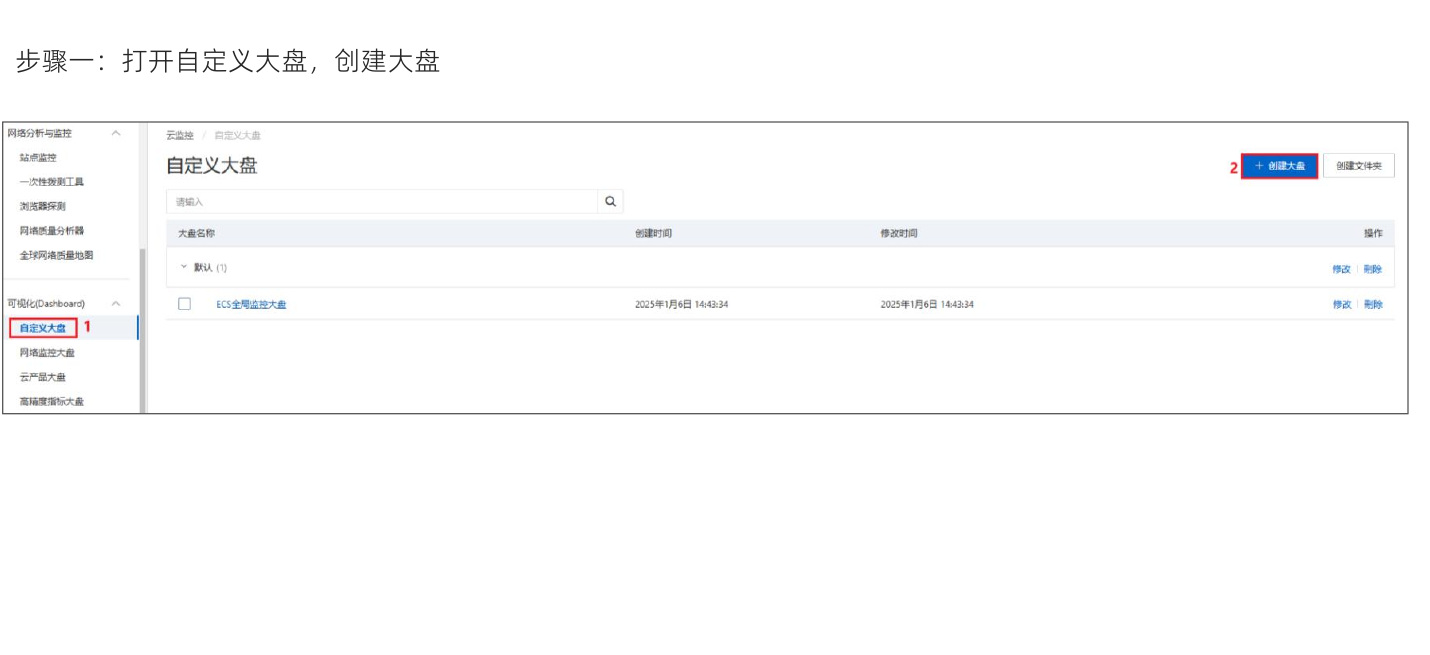

### 9.2 添加 CPU 使用率折线图

按课件的 CPU 示例配置：

| 配置项 | 示例选择 |
| --- | --- |
| 云产品 | 云服务器 ECS |
| 监控指标 | 实例维度 / (ECS)CPU使用率 |
| 统计方法 | 平均值 |
| 所属维度 | `instanceId` |
| 图表类型 | 折线图 |
| 图表名称 | CPU使用率 |

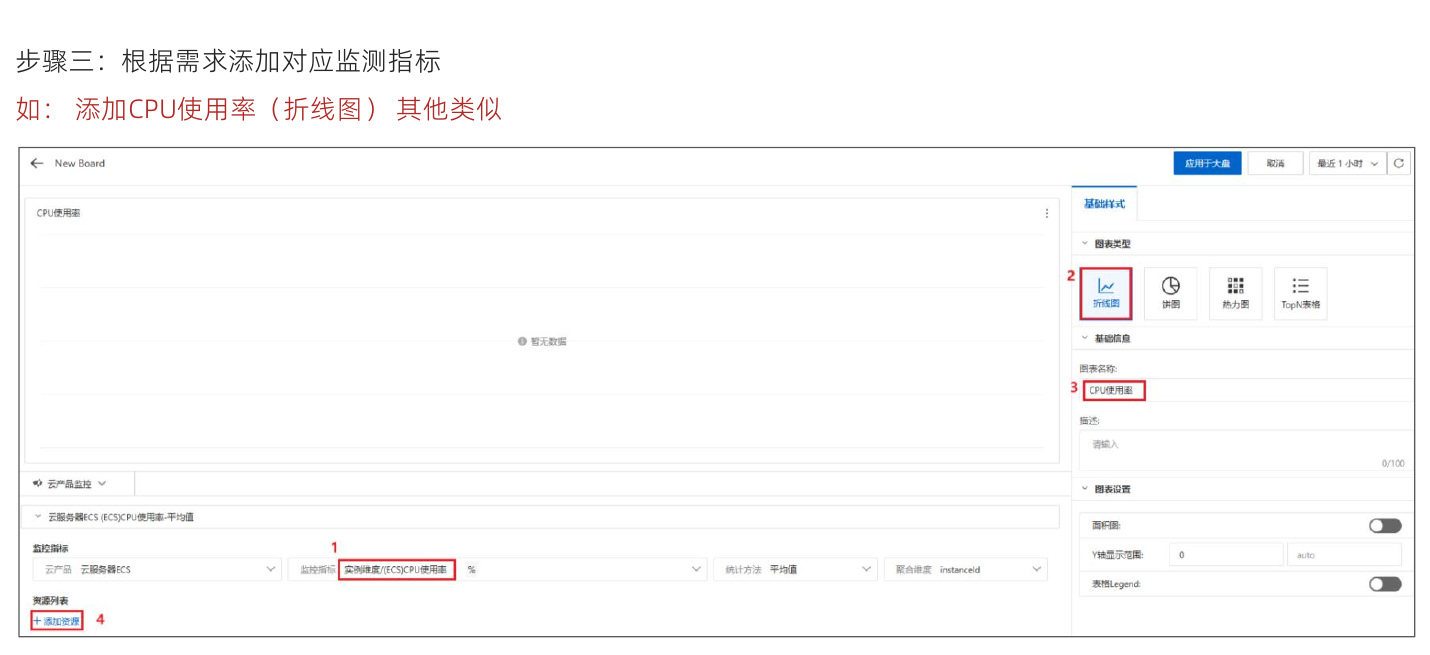

点击下方“添加资源”，在资源选择窗口中：

1. 选择“云产品实例选择”。
2. 按地域筛选，勾选需要展示的实例。
3. 点击“确定”，返回图表编辑页面。
4. 确认资源和图表配置后，点击“应用于大盘”。

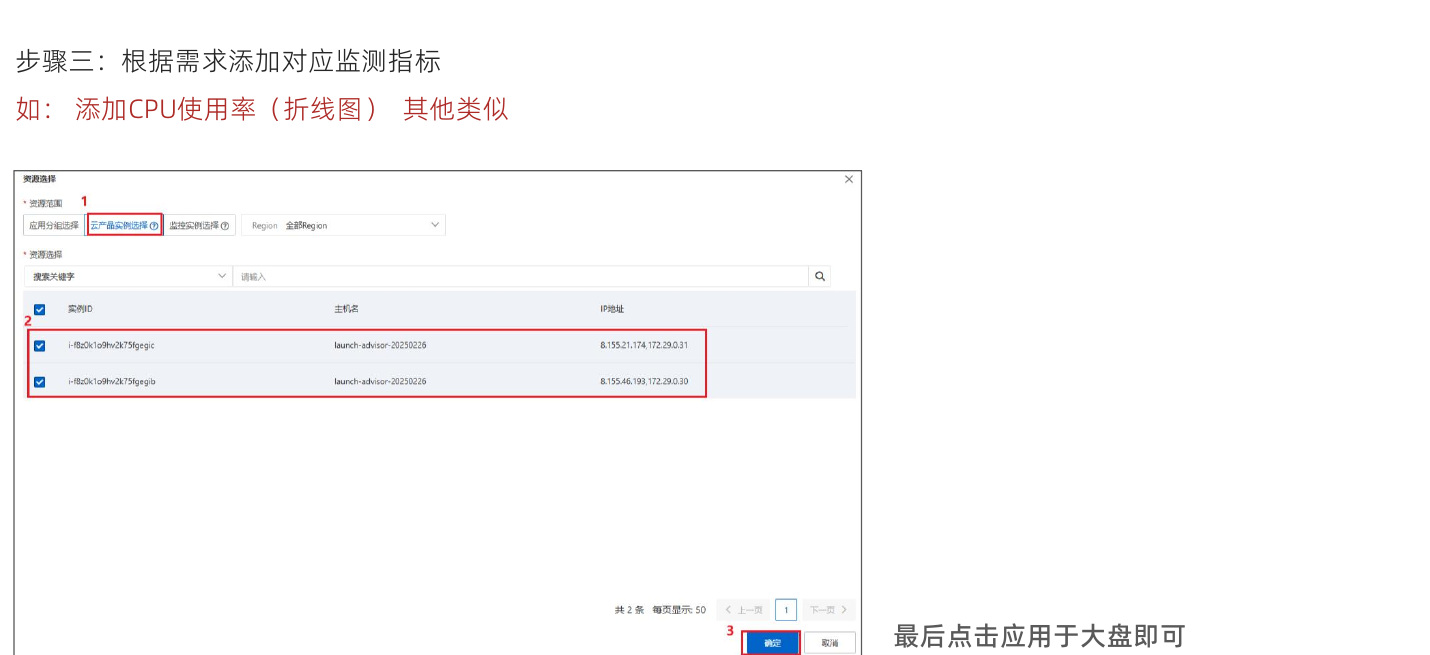

这里的资源选择决定曲线来自哪些 ECS。只给图表起名，没有选择资源，还不能形成有效的监控图表。

### 9.3 添加其他指标并保存

重复“添加图表 → 选择指标 → 选择资源 → 应用于大盘”，按需要添加内存、网络等指标。课件界面还提供饼图、热力图和 TopN 表格等图表类型。

完成后点击“保存大盘”，填写大盘名称，选择所属文件夹，再点击“确定”。

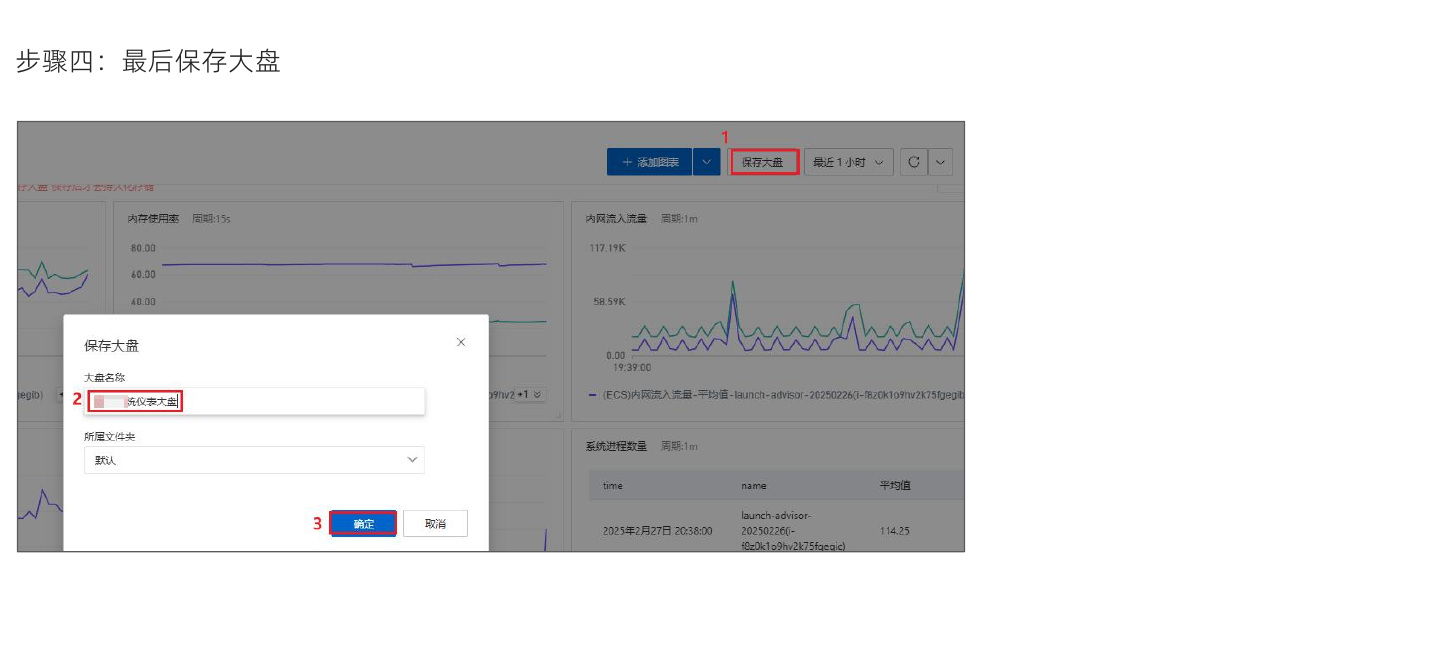

**验证：** 返回大盘列表后重新进入，确认图表保留、资源正确，并在统一的时间范围内看到实际数据。课件演示页面可以选择“最近 1 小时”等范围，以及刷新和全屏显示。

课件最终大盘展示了 CPU 使用率、内存使用率、内网流入流量、实例网络连接数、过去 5 分钟的系统单核平均负载、系统进程数量、磁盘使用率、空闲 CPU 占用和网卡每秒发送的数据包数量。各图的指标及统计周期可以不同；横向比较时要先看图表标题、单位和周期。

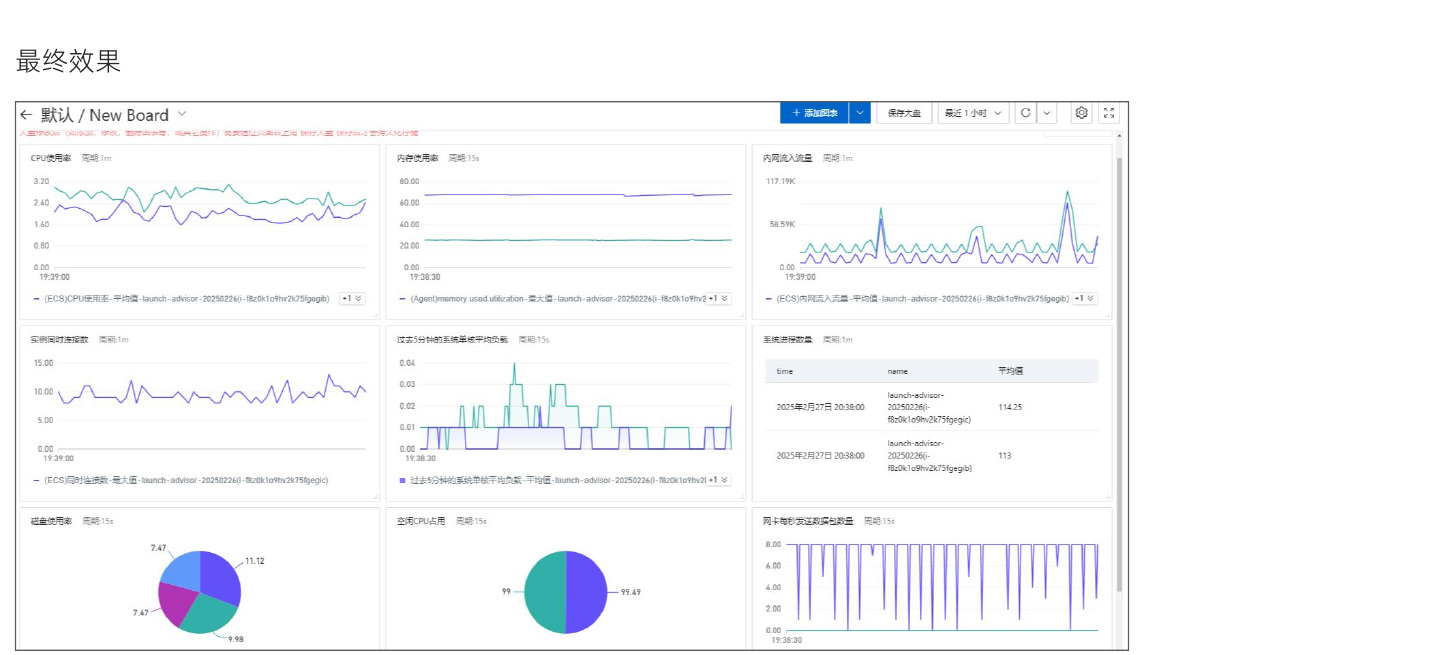

大盘用来集中查看指标，报警规则用来在条件满足时通知人员；两项配置都完成后，才能同时做到持续观察和及时获知异常。
